# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [4]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a line chart indexed to 1970 (1970 = 100) because it is the most effective way to compare continuous relative growth trajectories across continents over time from a common baseline. Highlighting Africa in bold blue while keeping the remaining five continents in muted grey eliminates clutter and immediately draws attention to the fastest-growing region.*

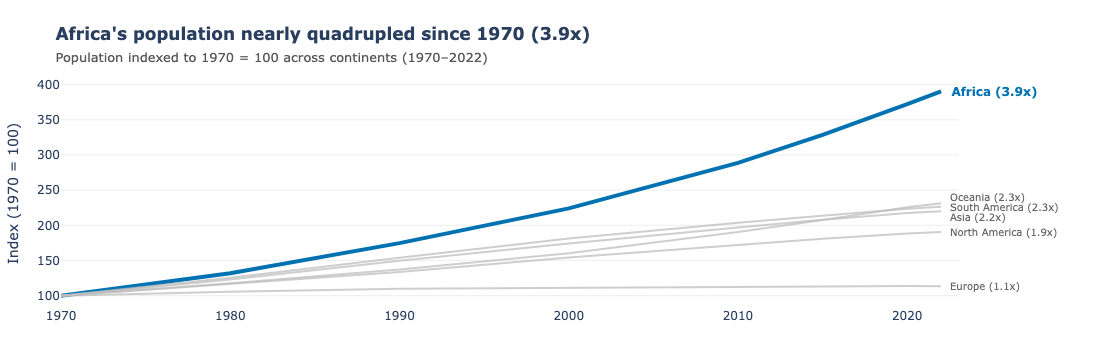

In [5]:
# Q1
# YOUR CODE HERE

cont_year = (
    df_long.groupby(["Continent", "Year"], as_index=False)["Population"]
    .sum()
    .sort_values(["Continent", "Year"])
)

# Index each continent to its 1970 population (1970 = 100)
pop_1970 = cont_year[cont_year["Year"] == 1970].set_index("Continent")[
    "Population"
]
cont_year["Index_1970"] = (
    cont_year["Population"] / cont_year["Continent"].map(pop_1970) * 100
)

# CVD-safe palette: Okabe-Ito Blue for Africa, muted grey for context
continents = cont_year["Continent"].unique()
color_map = {c: ("#0072B2" if c == "Africa" else "#BDBDBD") for c in continents}

fig = px.line(
    cont_year,
    x="Year",
    y="Index_1970",
    color="Continent",
    color_discrete_map=color_map,
    template="plotly_white",
)

# Emphasize Africa's line thickness and bring it to front
fig.update_traces(line=dict(width=2), opacity=0.75)
fig.update_traces(
    selector=dict(name="Africa"), line=dict(width=4), opacity=1.0
)

# Direct end-of-line labels instead of a legend
end_vals = cont_year[cont_year["Year"] == 2022].sort_values(
    "Index_1970", ascending=False
)
for _, row in end_vals.iterrows():
    c = row["Continent"]
    y_val = row["Index_1970"]
    # Slight vertical offset for overlapping labels around 220-231
    y_shift = (
        6
        if c == "Oceania"
        else (-6 if c == "Asia" else (0 if c == "South America" else 0))
    )
    fig.add_annotation(
        x=2022,
        y=y_val,
        text=f"  <b>{c} ({y_val/100:.1f}x)</b>"
        if c == "Africa"
        else f"  {c} ({y_val/100:.1f}x)",
        showarrow=False,
        xanchor="left",
        yshift=y_shift,
        font=dict(
            size=12 if c == "Africa" else 10,
            color="#0072B2" if c == "Africa" else "#666666",
        ),
    )

fig.update_layout(
    title=(
        "<b>Africa's population nearly quadrupled since 1970 (3.9x)</b>"
        "<br><span style='font-size:13px; color:#555;'>Population indexed to"
        " 1970 = 100 across continents (1970–2022)</span>"
    ),
    showlegend=False,
    margin=dict(r=150, t=80, l=50, b=40),
    hovermode="x unified",
)
fig.update_xaxes(title="", showgrid=False, range=[1970, 2023])
fig.update_yaxes(
    title="Index (1970 = 100)", showgrid=True, gridcolor="#EEEEEE", zeroline=False
)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a horizontal sorted bar chart because ranking discrete countries by absolute population gain allows effortless left-to-right length comparison and keeps country names readable without text rotation. Encoding African nations in Okabe-Ito orange against light grey for all other continents immediately highlights that 4 of the top 15 countries are in Africa (Nigeria, Ethiopia, DR Congo, and Egypt).*

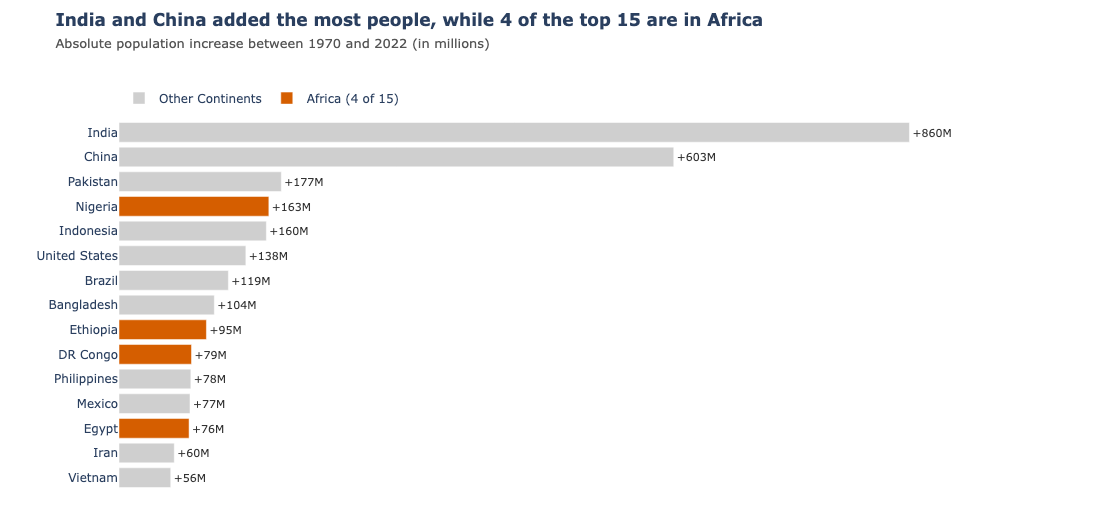

In [14]:
# Q2

df["Pop_Added"] = df["2022 Population"] - df["1970 Population"]
top15 = df.nlargest(15, "Pop_Added").sort_values("Pop_Added", ascending=True)
top15["Is_Africa"] = np.where(
    top15["Continent"] == "Africa", "Africa (4 of 15)", "Other Continents"
)
top15["Label"] = (top15["Pop_Added"] / 1e6).map(lambda x: f"+{x:,.0f}M")

fig = px.bar(
    top15,
    x="Pop_Added",
    y="Country",
    orientation="h",
    color="Is_Africa",
    text="Label",
    color_discrete_map={
        "Africa (4 of 15)": "#D55E00",
        "Other Continents": "#CFCFCF",
    },
    template="plotly_white",
)

fig.update_traces(
    textposition="outside",
    cliponaxis=False,
    textfont=dict(size=11, color="#333333"),
)

fig.update_layout(
    title=dict(
        text=(
            "<b>India and China added the most people, while 4 of the top 15"
            " are in Africa</b><br><span style='font-size:13px;"
            " color:#555;'>Absolute population increase between 1970 and 2022"
            " (in millions)</span>"
        ),
        y=0.95,  # Raises the title/subtitle block cleanly above the legend
        yanchor="top",
    ),
    legend=dict(
        title="",
        orientation="h",
        yanchor="bottom",
        y=1.02,  # Keeps a clear vertical gap below the subtitle
        xanchor="left",
        x=0,
    ),
    margin=dict(r=80, t=120, l=110, b=30),  # Extra top margin for breathing room
    height=520,
)

fig.update_xaxes(visible=False, range=[0, top15["Pop_Added"].max() * 1.15])
fig.update_yaxes(
    title="",
    showgrid=False,
    categoryorder="total ascending",  # Keeps all 15 bars strictly sorted by length
)
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a scatter plot on log–log scales because both land area and population span multiple orders of magnitude, and a scatter plot clearly reveals their positive linear scaling (r = 0.87 in log space) across continents. Coloring by a CVD-safe continent palette and annotating extreme outliers (such as tiny, ultra-dense microstates like Monaco/Vatican City, vast sparsely populated countries like Canada/Russia, and massive populations in India/China) directly answers both parts of the question.*

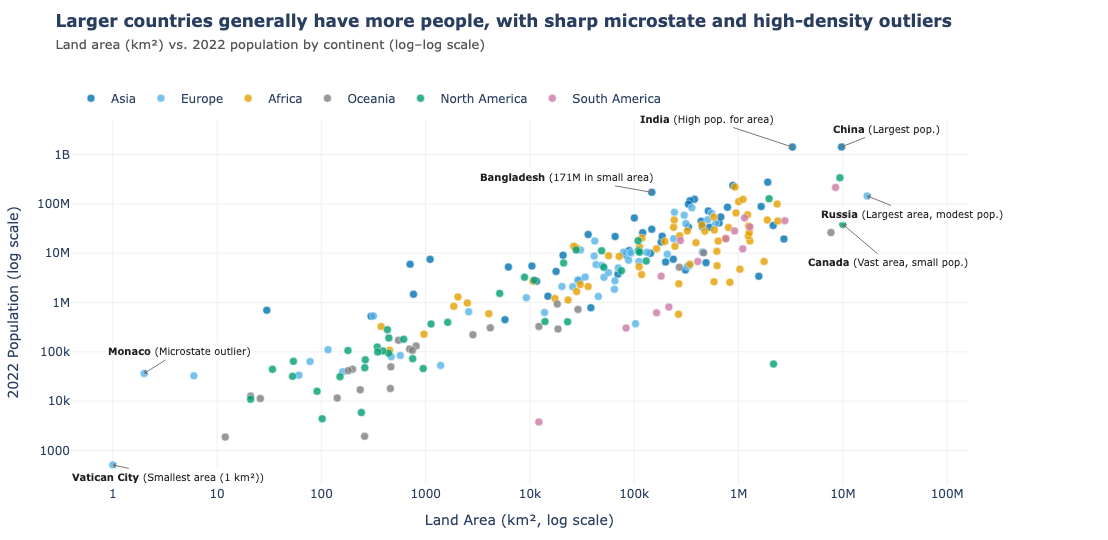

In [15]:
# Q3

okabe_ito = {
    "Asia": "#0072B2",
    "Africa": "#E69F00",
    "Europe": "#56B4E9",
    "North America": "#009E73",
    "South America": "#CC79A7",
    "Oceania": "#7F7F7F",
}

fig = px.scatter(
    df,
    x="Area",
    y="2022 Population",
    color="Continent",
    hover_name="Country",
    log_x=True,
    log_y=True,
    color_discrete_map=okabe_ito,
    template="plotly_white",
)

fig.update_traces(
    marker=dict(size=8, opacity=0.8, line=dict(width=0.5, color="white"))
)

# Spread annotations in distinct directions (ax, ay in pixels) so none overlap
outliers = [
    ("China", "Largest pop.", 45, -18),  # Up and right
    ("India", "High pop. for area", -85, -28),  # Up and left
    ("Russia", "Largest area, modest pop.", 45, 18),  # Down and right
    ("Canada", "Vast area, small pop.", 45, 38),  # Further down and right
    ("Bangladesh", "171M in small area", -85, -15),  # Up and left
    ("Monaco", "Microstate outlier", 35, -22),  # Up and right
    ("Vatican City", "Smallest area (1 km²)", 55, 12),  # Down and right
]

for country, note, ax, ay in outliers:
    row = df[df["Country"] == country].iloc[0]
    fig.add_annotation(
        x=np.log10(row["Area"]),
        y=np.log10(row["2022 Population"]),
        text=f"<b>{country}</b> ({note})",
        showarrow=True,
        arrowhead=1,
        arrowwidth=1,
        arrowcolor="#777777",
        ax=ax,
        ay=ay,
        bgcolor="rgba(255, 255, 255, 0.85)",  # Clean background behind text
        borderpad=2,
        font=dict(size=10, color="#222222"),
    )

fig.update_layout(
    title=dict(
        text=(
            "<b>Larger countries generally have more people, with sharp"
            " microstate and high-density outliers</b><br><span"
            " style='font-size:13px; color:#555;'>Land area (km²) vs. 2022"
            " population by continent (log–log scale)</span>"
        ),
        y=0.95,  # Keeps clear space above the legend
        yanchor="top",
    ),
    legend=dict(
        title="",
        orientation="h",
        yanchor="bottom",
        y=1.02,  # Clear vertical gap below the subtitle
        xanchor="left",
        x=0,
    ),
    margin=dict(t=120, l=65, r=140, b=55),  # Extra right & top margin for labels
    height=540,
)

fig.update_xaxes(
    title="Land Area (km², log scale)",
    showgrid=True,
    gridcolor="#F0F0F0",
    range=[-0.4, 8.2],  # Prevents right-side labels from clipping
)
fig.update_yaxes(
    title="2022 Population (log scale)",
    showgrid=True,
    gridcolor="#F0F0F0",
    range=[2.3, 9.7],  # Gives headroom at top for China & India labels
)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a box plot (with overlaid individual country points and a log scale) because it displays the median, interquartile range (middle 50%), and extreme outliers simultaneously across continents rather than hiding skewness behind a simple mean. Using a neutral blue-grey fill for the boxes highlights Asia's higher median density (123/km²), South America's consistently low density (median 18/km²), and extreme city-state outliers like Macau and Monaco.*

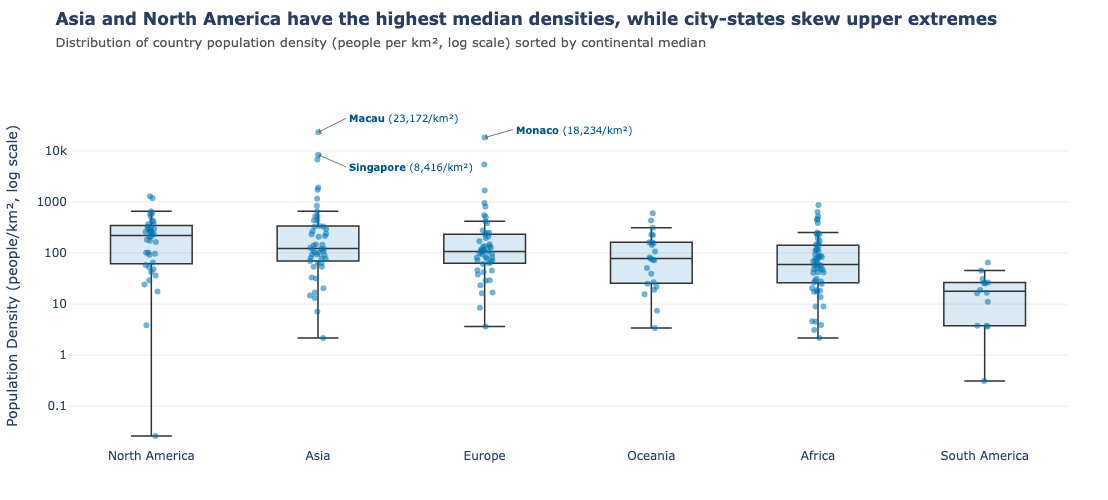

In [21]:
# Q4
order = (
    df.groupby("Continent")["Density"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

fig = px.box(
    df,
    x="Continent",
    y="Density",
    category_orders={"Continent": order},
    points="all",
    hover_name="Country",
    log_y=True,
    template="plotly_white",
)

fig.update_traces(
    marker=dict(color="#0072B2", opacity=0.55, size=6),
    line=dict(color="#333333", width=1.5),
    fillcolor="rgba(0, 114, 178, 0.15)",
    jitter=0.2,
    pointpos=0,
)

# Separate Macau, Singapore, and Monaco with distinct arrow directions
outliers = [
    ("Macau", 28, -14),  # Upper right of Macau dot (23,172)
    ("Singapore", 28, 12),  # Lower right of Singapore dot (8,416)
    ("Monaco", 28, -8),  # Right of Monaco dot (18,234)
]

for country, ax, ay in outliers:
    row = df[df["Country"] == country].iloc[0]
    fig.add_annotation(
        x=row["Continent"],
        y=np.log10(row["Density"]),
        text=f"<b>{country}</b> ({row['Density']:,.0f}/km²)",
        showarrow=True,
        arrowhead=1,
        arrowwidth=1,
        arrowcolor="#777777",
        ax=ax,
        ay=ay,
        xanchor="left",
        bgcolor="rgba(255, 255, 255, 0.85)",
        borderpad=2,
        font=dict(size=10, color="#005587"),
    )

fig.update_layout(
    title=dict(
        text=(
            "<b>Asia and North America have the highest median densities, while"
            " city-states skew upper extremes</b><br><span"
            " style='font-size:13px; color:#555;'>Distribution of country"
            " population density (people per km², log scale) sorted by"
            " continental median</span>"
        ),
        y=0.95,
        yanchor="top",
    ),
    margin=dict(t=105, l=65, r=40, b=45),
    height=500,
)

fig.update_xaxes(title="", showgrid=False)
fig.update_yaxes(
    title="Population Density (people/km², log scale)",
    showgrid=True,
    gridcolor="#EEEEEE",
    range=[-1.8, 4.9],  # Adds headroom above Macau (log10(23172) ≈ 4.36)
)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a choropleth map because the question explicitly asks where in the world populations grew or shrank, making geographic position essential for spotting regional clusters (rapid growth across Sub-Saharan Africa and the Middle East versus decline in Eastern Europe and parts of Oceania). A diverging purple–white–blue/teal (PuBu / custom CVD-safe diverging) color scale centered at 0% cleanly separates shrinkage from growth without using red or green.*

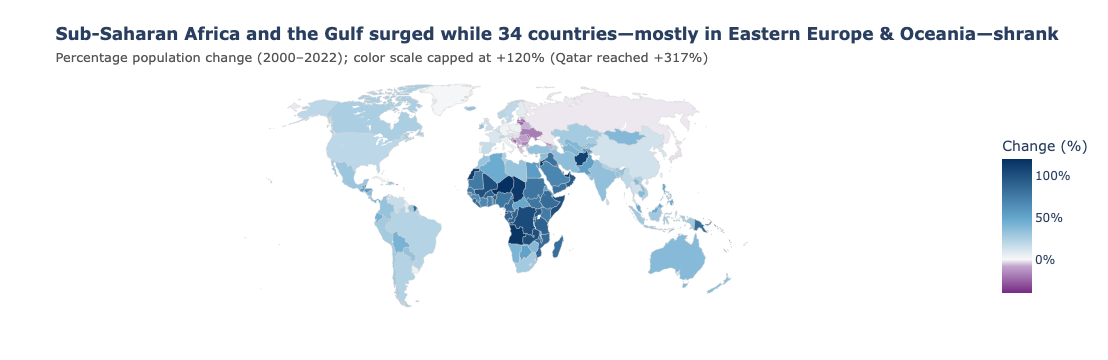

In [11]:
# Q5

df["Pct_Change_00_22"] = (
    (df["2022 Population"] - df["2000 Population"]) / df["2000 Population"]
) * 100

# CVD-safe diverging palette: Purple (shrinkage) -> Light Neutral (0%) -> Blue (growth)
cvd_diverging = [
    [0.0, "#762A83"],   # Strong shrinkage (-40%)
    [0.2, "#C2A5CF"],   # Mild shrinkage
    [0.25, "#F7F7F7"],  # 0% midpoint (given range -40 to +120)
    [0.55, "#67A9CF"],  # Moderate growth
    [1.0, "#053061"],   # Rapid growth (+120%+)
]

fig = px.choropleth(
    df,
    locations="CCA3",
    locationmode="ISO-3",
    color="Pct_Change_00_22",
    hover_name="Country",
    hover_data={
        "CCA3": False,
        "Continent": True,
        "Pct_Change_00_22": ":.1f",
    },
    color_continuous_scale=cvd_diverging,
    range_color=[-40, 120],
    template="plotly_white",
)

fig.update_traces(marker_line_color="#CCCCCC", marker_line_width=0.4)

fig.update_layout(
    title=(
        "<b>Sub-Saharan Africa and the Gulf surged while 34 countries—mostly"
        " in Eastern Europe & Oceania—shrank</b><br><span"
        " style='font-size:13px; color:#555;'>Percentage population change"
        " (2000–2022); color scale capped at +120% (Qatar reached +317%)</span>"
    ),
    geo=dict(
        showframe=False,
        showcoastlines=False,
        projection_type="natural earth",
    ),
    coloraxis_colorbar=dict(
        title="Change (%)",
        ticksuffix="%",
        len=0.65,
    ),
    margin=dict(t=80, l=10, r=10, b=10),
)
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a treemap because it encodes hierarchical part-to-whole structure—displaying both continental totals and individual country shares within a single compact rectangle. Coloring continents with a muted CVD-safe palette and displaying direct labels with country names and population shares makes it immediately clear that Asia holds nearly 60% of humanity, led heavily by China and India.*

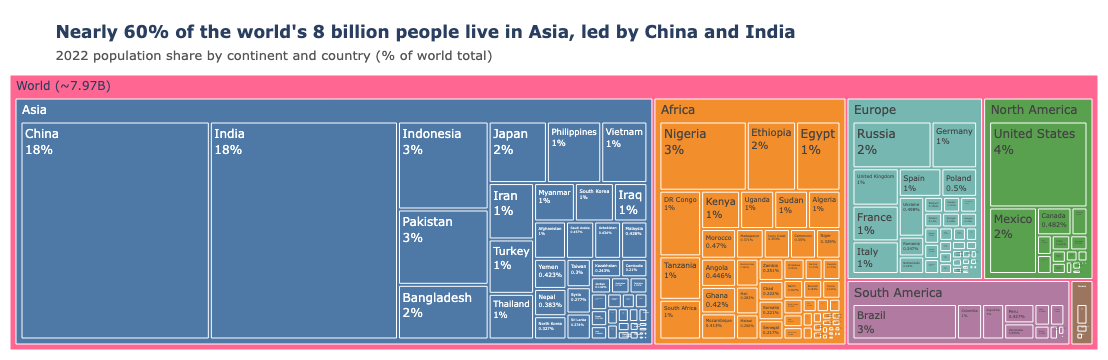

In [12]:
# Q6

okabe_ito_soft = {
    "Asia": "#4E79A7",
    "Africa": "#F28E2B",
    "Europe": "#76B7B2",
    "North America": "#59A14F",
    "South America": "#B07AA1",
    "Oceania": "#9C755F",
}

fig = px.treemap(
    df,
    path=[px.Constant("World (~7.97B)"), "Continent", "Country"],
    values="2022 Population",
    color="Continent",
    color_discrete_map=okabe_ito_soft,
    template="plotly_white",
)

fig.update_traces(
    textinfo="label+percent root",
    marker=dict(line=dict(width=1, color="white")),
    root_color="#F5F5F5",
    hovertemplate="<b>%{label}</b><br>Population: %{value:,}<br>World Share: %{percentRoot:.2%}<extra></extra>",
)

fig.update_layout(
    title=(
        "<b>Nearly 60% of the world's 8 billion people live in Asia, led by"
        " China and India</b><br><span style='font-size:13px;"
        " color:#555;'>2022 population share by continent and country (% of"
        " world total)</span>"
    ),
    margin=dict(t=75, l=10, r=10, b=10),
)
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*I chose a 100% stacked bar chart across the sampled years because it explicitly constrains every year's total to 100%, showing the zero-sum shift in global population share over time. Highlighting Africa in warm orange (#E69F00) and Europe in cool sky blue (#56B4E9) against neutral greys for Asia and the Rest of the World clearly isolates the primary structural shift: Africa's share rose from 9.9% to 17.9% while Europe's fell from 17.8% to 9.3%.*

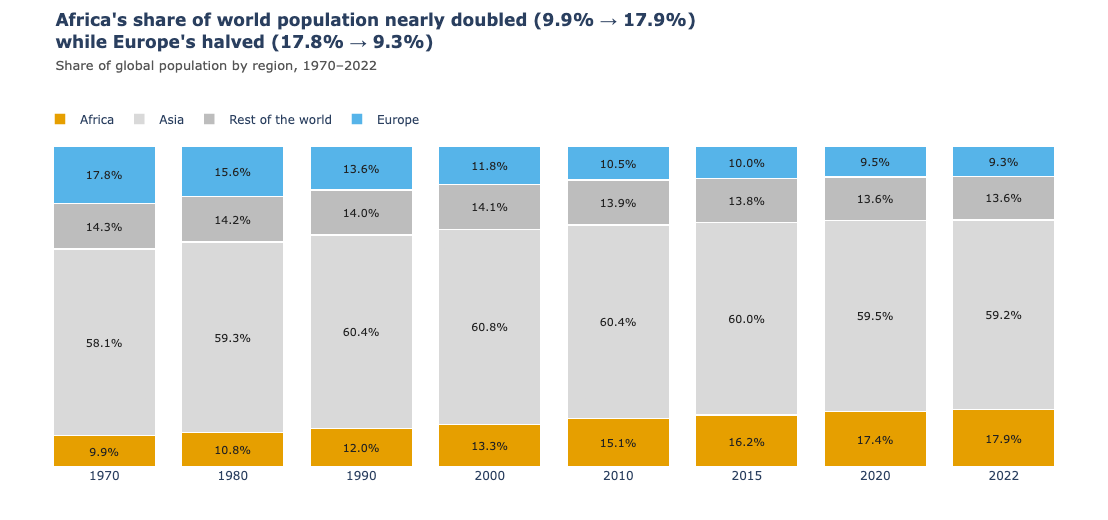

In [19]:
# Q7
df_long["Region"] = np.where(
    df_long["Continent"].isin(["Africa", "Asia", "Europe"]),
    df_long["Continent"],
    "Rest of the world",
)

reg_year = df_long.groupby(["Year", "Region"], as_index=False)["Population"].sum()
reg_year["Share"] = (
    reg_year["Population"]
    / reg_year.groupby("Year")["Population"].transform("sum")
    * 100
)
reg_year["Year_str"] = reg_year["Year"].astype(str)
reg_year["Label"] = reg_year["Share"].map(lambda x: f"{x:.1f}%")

region_order = ["Africa", "Asia", "Rest of the world", "Europe"]
region_colors = {
    "Africa": "#E69F00",  # Accent 1: Rising share (CVD-safe orange)
    "Asia": "#D9D9D9",  # Context grey 1
    "Rest of the world": "#BDBDBD",  # Context grey 2
    "Europe": "#56B4E9",  # Accent 2: Shrinking share (CVD-safe sky blue)
}

fig = px.bar(
    reg_year,
    x="Year_str",
    y="Share",
    color="Region",
    text="Label",
    category_orders={"Region": region_order},
    color_discrete_map=region_colors,
    template="plotly_white",
)

fig.update_traces(
    textposition="inside",
    insidetextanchor="middle",
    marker_line_color="white",
    marker_line_width=1.5,
    textfont=dict(size=11, color="#222222"),
)

fig.update_layout(
    barmode="stack",
    title=dict(
        text=(
            "<b>Africa's share of world population nearly doubled (9.9% →"
            " 17.9%)<br>while Europe's halved (17.8% → 9.3%)</b><br><span"
            " style='font-size:13px; color:#555;'>Share of global population"
            " by region, 1970–2022</span>"
        ),
        y=0.95,
        yanchor="top",
    ),
    legend=dict(
        title="",
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0,
        traceorder="normal",
        # No entrywidth here so each label gets full natural width + clean gap
    ),
    margin=dict(t=140, l=40, r=40, b=40),
    height=520,
)

fig.update_xaxes(title="", showgrid=False)
fig.update_yaxes(visible=False, range=[0, 102])
fig.show()